**Project Description:**

This time series data project uses a Beijing Air Quality dataset ([Beijing Multi-Site Air Quality](https://https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data$0)).
It contains data from 12 different stations. For this project we will be using the data from the Wanshouxigong station.

The data will be used to predict PM2.5 concentration using PM10, SO2, NO2, CO, O3, temperature, precipitation, DEWP, rain, wd, and WSPM as features.

Our motivation to predict PM2.5 is that this particulate matter creates a health risk. If we are able to accurately predict high levels of PM2.5 in the air, people in the local area can prepare and reschedule acitivities that may expose them to the harmful air in advance.

**Stage 1: Data, baselines, MLP**

In [21]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

import tensorflow as tf
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten

import keras as keras
import seaborn as sns


In [22]:
df = pd.read_csv("/content/PRSA_Data_Wanshouxigong_20130301-20170228.csv")
df['Date'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']]) # Creates a date column out of day, month, year, hour columns
df = df.sort_values("Date").set_index("Date").asfreq("H") # Makes the date column the index and adds missing rows in timeline as blank.

# Data Exploration
display(df.head(10))
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))



/tmp/ipykernel_1030/250133988.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df = df.sort_values("Date").set_index("Date").asfreq("H") # Makes the date column the index and adds missing rows in timeline as blank.


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
Date,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,9.0,9.0,6.0,17.0,200.0,62.0,0.3,1021.9,-19.0,0.0,WNW,2.0,Wanshouxigong
2013-03-01 01:00:00,2,2013,3,1,1,11.0,11.0,7.0,14.0,200.0,66.0,-0.1,1022.4,-19.3,0.0,WNW,4.4,Wanshouxigong
2013-03-01 02:00:00,3,2013,3,1,2,8.0,8.0,NaN,16.0,200.0,59.0,-0.6,1022.6,-19.7,0.0,WNW,4.7,Wanshouxigong
2013-03-01 03:00:00,4,2013,3,1,3,8.0,8.0,3.0,16.0,NaN,NaN,-0.7,1023.5,-20.9,0.0,NW,2.6,Wanshouxigong
2013-03-01 04:00:00,5,2013,3,1,4,8.0,8.0,3.0,NaN,300.0,36.0,-0.9,1024.1,-21.7,0.0,WNW,2.5,Wanshouxigong
2013-03-01 05:00:00,6,2013,3,1,5,10.0,10.0,4.0,8.0,200.0,64.0,-1.6,1024.7,-21.1,0.0,NE,2.0,Wanshouxigong
2013-03-01 06:00:00,7,2013,3,1,6,8.0,8.0,6.0,13.0,300.0,61.0,-2.4,1025.4,-20.3,0.0,NE,2.3,Wanshouxigong
2013-03-01 07:00:00,8,2013,3,1,7,8.0,8.0,8.0,20.0,300.0,54.0,-0.8,1026.7,-19.9,0.0,NNE,2.0,Wanshouxigong
2013-03-01 08:00:00,9,2013,3,1,8,3.0,6.0,9.0,23.0,300.0,50.0,0.4,1027.3,-19.4,0.0,NE,2.7,Wanshouxigong


Date range: 2013-03-01 to 2017-02-28
Shape: (35064, 18)

Columns: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']


Target: PM2.5 (µg/m^3)
Duplicate Timestamps:  0
Hours inserted by asfreq (missing rows): 0

Missing Values per Column (%): 
No       0.00
year     0.00
month    0.00
day      0.00
hour     0.00
PM2.5    1.98
PM10     1.38
SO2      1.91
NO2      2.15
CO       3.70
O3       3.07
TEMP     0.05
PRES     0.05
DEWP     0.05
RAIN     0.05
WSPM     0.04
dtype: float64


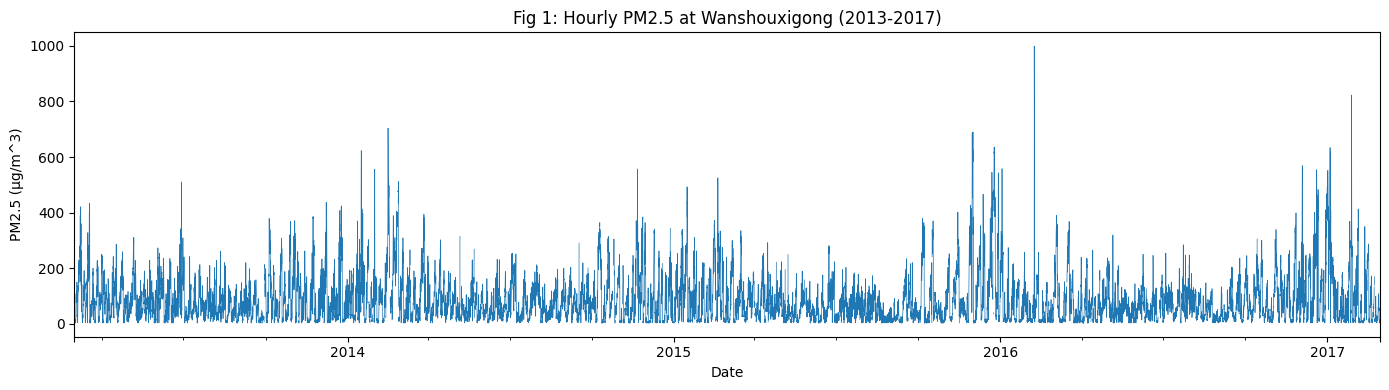

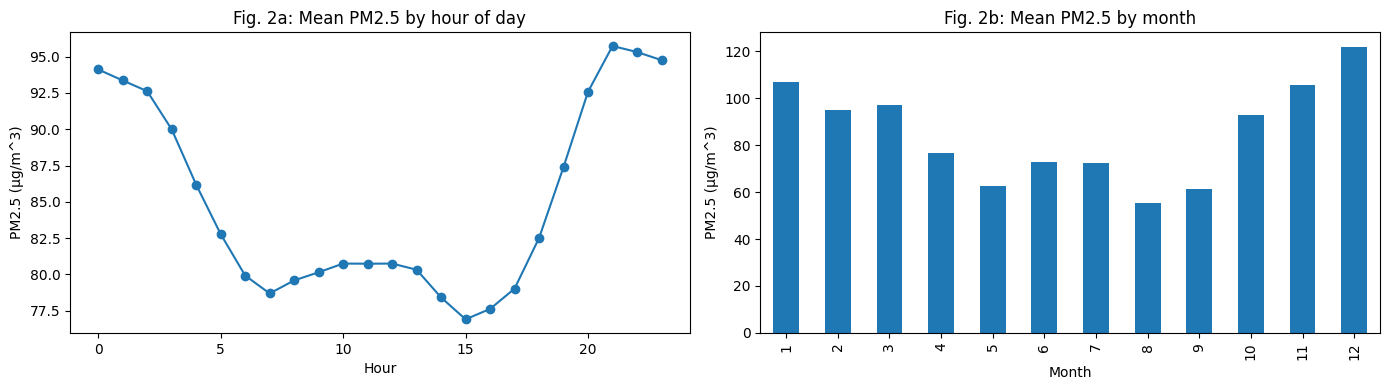

In [23]:
# Data audit
print("Target: PM2.5 (µg/m^3)")
print("Duplicate Timestamps: ", df.index.duplicated().sum()) # Counts repeated timestamps in the index
print("Hours inserted by asfreq (missing rows):", df['No'].isna().sum()) # 'No' is never missing in the raw file, so any NaN here is a row asfreq added
print("\nMissing Values per Column (%): ")
print((df[df.select_dtypes("number").columns].isna().mean() * 100).round(2)) # Percent of missing values in each numeric column

# Fig. 1: PM2.5 over the full time range
fig, ax = plt.subplots(figsize=(14, 4))
df['PM2.5'].plot(ax=ax, lw=0.5) # Thin line so the dense hourly data stays readable
ax.set_title("Fig 1: Hourly PM2.5 at Wanshouxigong (2013-2017)")
ax.set_ylabel("PM2.5 (µg/m^3)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

# Fig. 2: Daily and seasonal patterns
fig, axes = plt.subplots(1, 2, figsize = (14, 4))

# Fig. 2a: Average PM2.5 for each hour of the day
df['PM2.5'].groupby(df.index.hour).mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Fig. 2a: Mean PM2.5 by hour of day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("PM2.5 (µg/m^3)")

# Fig. 2b: Average PM2.5 for each month of the year
df['PM2.5'].groupby(df.index.month).mean().plot(kind="bar", ax = axes[1])
axes[1].set_title("Fig. 2b: Mean PM2.5 by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("PM2.5 (µg/m^3)")

plt.tight_layout()
plt.show()

Missing Values per Column:
No            0
year          0
month         0
day           0
hour          0
PM2.5       696
PM10        484
SO2         669
NO2         754
CO         1297
O3         1078
TEMP         19
PRES         19
DEWP         19
RAIN         19
wd           79
WSPM         13
station       0
dtype: int64

Total Duplicate Rows: 0


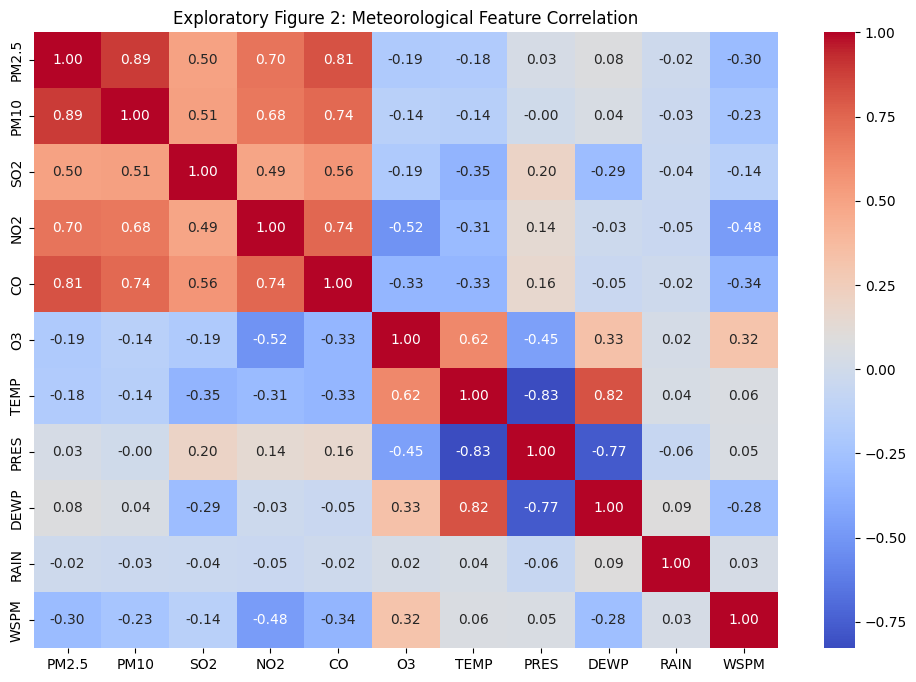

In [24]:
# Dataset Integrity Checks
print(f"Missing Values per Column:\n{df.isna().sum()}\n")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")

# Figure 2: Feature Correlation Heatmap
plt.figure(figsize=(12, 8))
corr_matrix = df[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Exploratory Figure 2: Meteorological Feature Correlation')
plt.show()

**Data Audit Findings**

- There are no duplicate timestamps, and 'asfreq inserted 0 rows'. This means the dataset's hourly timeline is complete with no missing hours.
- Any missing data is found in individual values within the existing rows. The amount of missing data is small, with CO and O3 being the worst at 3.70% and 3.07% respectively. Meteorological variables are only missing in approximately 0.05% of rows.
- Due to no hours being missing, forward fill is the most reasonabl imputation here. It is fit seperately within each split, so no information crosses from validation or test into training

**Figure Interpretations**

- Fig 1: PM2.5 is very spiky and right-skewed. Most hours sit below approximately 200µg/m^3, with short extreme episodes peaking around 700 in early 2014 and close to 1000 in early 2016. These extreme episodes appear to cluster in cooler months each year, and mid-2015 stands out as relatively clean. These spikes are the most difficult part of the task, and they are the events our health motivation cares about most.

- Fig 2a: PM2.5 is highest in the evening and overnight (peaking near 96µg/m^3 around 21:00) and lowest in the mid-afternoon (about 77 µg/m^3 around 15:00). The daily swing is fairly modest compared with the hour-to-hour spikes in Fig 1

- Fig 2b: The winter months are visibly worse, with December highest (about 122 µg/m^3), followed by January and November. August is lowest at around 55 µg/m^3. The pattern is consistent with a heating-season effect, though the cause has not yet been tested.

- Implication: both patterns suggest the previous 24 hours carry real signal, and that a model may do worse in winter when levels are higher and more volatile than warmer months.

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Identifying features and target
numeric_variables = ['PM2.5','PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
cat_variables = ['wd']
target = 'PM2.5'

# Train/Validation Split
train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

train = df.iloc[:train_end].copy()
val   = df.iloc[train_end:val_end].copy()
test  = df.iloc[val_end:].copy()

# Imputing data using forward fill
train[numeric_variables] = train[numeric_variables].ffill()
val[numeric_variables] = val[numeric_variables].ffill()
test[numeric_variables] = test[numeric_variables].ffill()

train[cat_variables] = train[cat_variables].ffill()
val[cat_variables] = val[cat_variables].ffill()
test[cat_variables] = test[cat_variables].ffill()

# Scaling data (numeric variables only)
scaler = StandardScaler()
train_num_scaled = scaler.fit_transform(train[numeric_variables].to_numpy())
val_num_scaled = scaler.transform(val[numeric_variables].to_numpy())
test_num_scaled = scaler.transform(test[numeric_variables].to_numpy())

# One hot encoding the wind direction
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
train_cat_encoded = encoder.fit_transform(train[cat_variables])
val_cat_encoded = encoder.transform(val[cat_variables])
test_cat_encoded = encoder.transform(test[cat_variables])

# Combine the processed categorical and numeric arrays
train_combined = np.hstack((train_num_scaled, train_cat_encoded))
val_combined = np.hstack((val_num_scaled, val_cat_encoded))
test_combined = np.hstack((test_num_scaled, test_cat_encoded))

# Make the windows for training
LOOKBACK = 24 # Lookback is 24 for 24 hours
def make_windows(values, lookback):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])
    return np.asarray(X), np.asarray(y)

X_train, y_train = make_windows(train_combined, LOOKBACK)
X_val, y_val = make_windows(val_combined, LOOKBACK)
X_test, y_test = make_windows(test_combined, LOOKBACK)




In [26]:
# Non neural network baselines with scaled units
y_true_val = y_val[:, pm25_idx] # Actual next-hour PM2.5 (scaled)

# Moving average: mean of the 24 hours in the window
y_pred_ma = np.mean(X_val[:, :, pm25_idx], axis=1)

# Persistence: next hour equals the last hour in the window
y_pred_persist = X_val[:, -1, pm25_idx]

# Seasonal naive: next hour equals the same hour yesterday (first step of the window)
y_pred_seasonal = X_val[:, 0, pm25_idx]

baseline_preds = {
    "Moving Average": y_pred_ma,
    "Persistence": y_pred_persist,
    "Seasonal Naive": y_pred_seasonal
}

for name, pred in baseline_preds.items():
    mae = mean_absolute_error(y_true_val, pred)
    rmse = np.sqrt(mean_squared_error(y_true_val, pred))
    print(f"{name}: MAE = {mae:.4f}, RMSE = {rmse:.4f}")

Moving Average: MAE = 0.4458, RMSE = 0.7386
Persistence: MAE = 0.1346, RMSE = 0.2732
Seasonal Naive: MAE = 0.6912, RMSE = 1.1290


In [27]:
# MLP


# Defining a Early-Stop method
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0,
    patience=5,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=True,
    start_from_epoch=0
    )

# Extract ONLY the PM2.5 column for the neural networks to predict
y_train_pm25 = y_train[:, pm25_idx]
y_val_pm25 = y_val[:, pm25_idx]
y_test_pm25 = y_test[:, pm25_idx]

num_features = X_train.shape[-1]


SEED = 42 # This is our seed so that each run is the same

mlp_model = Sequential([
    Input(shape=(LOOKBACK, num_features)),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(1)
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

mlp_history = mlp_model.fit(
    X_train, y_train_pm25,
    validation_data=(X_val, y_val_pm25),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

mlp_predictions = mlp_model.predict(X_val)
mlp_mae = mean_absolute_error(y_val_pm25, mlp_predictions)

# CNN
tf.keras.utils.set_random_seed(SEED)

cnn_model = Sequential([
    Input(shape=(LOOKBACK, num_features)),
    Conv1D(filters=16, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(16, activation="relu"),
    Dense(1)
])

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

cnn_history = cnn_model.fit(
    X_train, y_train_pm25,
    validation_data=(X_val, y_val_pm25),
    epochs=60,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

cnn_predictions = cnn_model.predict(X_val)
cnn_mae = mean_absolute_error(y_val_pm25, cnn_predictions)



print(f"Baseline (Moving Average): {baseline_mae:.4f}")
print(f"MLP Model: {mlp_mae:.4f}")
print(f"CNN Model: {cnn_mae:.4f}")

Epoch 1/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3456 - val_loss: 0.1829
Epoch 2/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2127 - val_loss: 0.1786
Epoch 3/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1412 - val_loss: 0.1390
Epoch 4/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1149 - val_loss: 0.1257
Epoch 5/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1056 - val_loss: 0.1191
Epoch 6/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0887 - val_loss: 0.1049
Epoch 7/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0903 - val_loss: 0.1166
Epoch 8/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0802 - val_loss: 0.1107
Epoch 9/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0790 - val_loss: 0.1066
Epoch 10/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0678 - val_loss: 0.1103
Epoch 11/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0834 - val_loss: 0.1009
Epoch 12/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

In [28]:
# Chronological split table
split_table = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Start": [train.index.min(), val.index.min(), test.index.min()],
    "End":   [train.index.max(), val.index.max(), test.index.max()],
    "Rows":  [len(train), len(val), len(test)],
    "Share (%)": [round(len(s) / len(df) * 100, 1) for s in (train, val, test)]
})
display(split_table)

# Window shapes (samples, timesteps, features)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
print("\nTarget vectors fed to the neural networks (PM2.5 only):")
print("y_train_pm25:", y_train_pm25.shape)

,Split,Start,End,Rows,Share (%)
0,Train,2013-03-01 00:00:00,2015-12-18 15:00:00,24544,70.0
1,Validation,2015-12-18 16:00:00,2016-07-24 19:00:00,5260,15.0
2,Test,2016-07-24 20:00:00,2017-02-28 23:00:00,5260,15.0


X_train: (24520, 24, 27) | y_train: (24520, 27)
X_val:   (5236, 24, 27) | y_val:   (5236, 27)
X_test:  (5236, 24, 27) | y_test:  (5236, 27)

Target vectors fed to the neural networks (PM2.5 only):
y_train_pm25: (24520,)


In [29]:
# Evaluation helper: converts scaled PM2.5 back to µg/m^3 and scores it
pm25_mean = scaler.mean_[pm25_idx]   # Mean of PM2.5 in the training set
pm25_std = scaler.scale_[pm25_idx]   # Std of PM2.5 in the training set

def to_ugm3(scaled_values):
    # Undo StandardScaler: x = scaled * std + mean
    return np.asarray(scaled_values).ravel() * pm25_std + pm25_mean

def evaluate(y_true_scaled, y_pred_scaled):
    # Returns MAE and RMSE in µg/m^3 so every model is scored identically
    y_true = to_ugm3(y_true_scaled)
    y_pred = to_ugm3(y_pred_scaled)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"MAE": mae, "RMSE": rmse}

# Score the three baselines in real units
y_true_val = y_val[:, pm25_idx]
for name, pred in baseline_preds.items():
    m = evaluate(y_true_val, pred)
    print(f"{name}: MAE = {m['MAE']:.2f} µg/m^3, RMSE = {m['RMSE']:.2f} µg/m^3")

Moving Average: MAE = 36.61 µg/m^3, RMSE = 60.66 µg/m^3
Persistence: MAE = 11.06 µg/m^3, RMSE = 22.44 µg/m^3
Seasonal Naive: MAE = 56.77 µg/m^3, RMSE = 92.72 µg/m^3


In [30]:
# Chronological split table
split_table = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Start": [train.index.min(), val.index.min(), test.index.min()],
    "End":   [train.index.max(), val.index.max(), test.index.max()],
    "Rows":  [len(train), len(val), len(test)],
    "Share (%)": [round(len(s) / len(df) * 100, 1) for s in (train, val, test)]
})
display(split_table)

# Window shapes (samples, timesteps, features)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
print("\nTarget vectors fed to the neural networks (PM2.5 only):")
print("y_train_pm25:", y_train_pm25.shape)

,Split,Start,End,Rows,Share (%)
0,Train,2013-03-01 00:00:00,2015-12-18 15:00:00,24544,70.0
1,Validation,2015-12-18 16:00:00,2016-07-24 19:00:00,5260,15.0
2,Test,2016-07-24 20:00:00,2017-02-28 23:00:00,5260,15.0


X_train: (24520, 24, 27) | y_train: (24520, 27)
X_val:   (5236, 24, 27) | y_val:   (5236, 27)
X_test:  (5236, 24, 27) | y_test:  (5236, 27)

Target vectors fed to the neural networks (PM2.5 only):
y_train_pm25: (24520,)



**Evaluation Setup: Split and Windows**

- Target: PM2.5 at hour t. Horizon: 1 hour ahead. Lookback: 24 hours of all features (11 numeric plus the one-hot wind direction columns).
- Split: chronological 70% / 15% / 15% with no shuffling, so the model is always evaluated on data that comes after what it trained on. The test set stays untouched until the final evaluation.
- Window shapes: each array is (samples, 24 timesteps, features). Every sample is the previous 24 hours, and its label is the next hour's PM2.5. Each split loses its first 24 rows, because the first window needs 24 hours of history.
- Leakage controls: the scaler and one-hot encoder are fit on the training split only, then applied to validation and test. Forward fill runs within each split separately.

,Model,Mean Absolute Error (MAE)
1,MLP,0.180268
2,1D CNN,0.273430
0,Baseline (Moving Average),0.445760


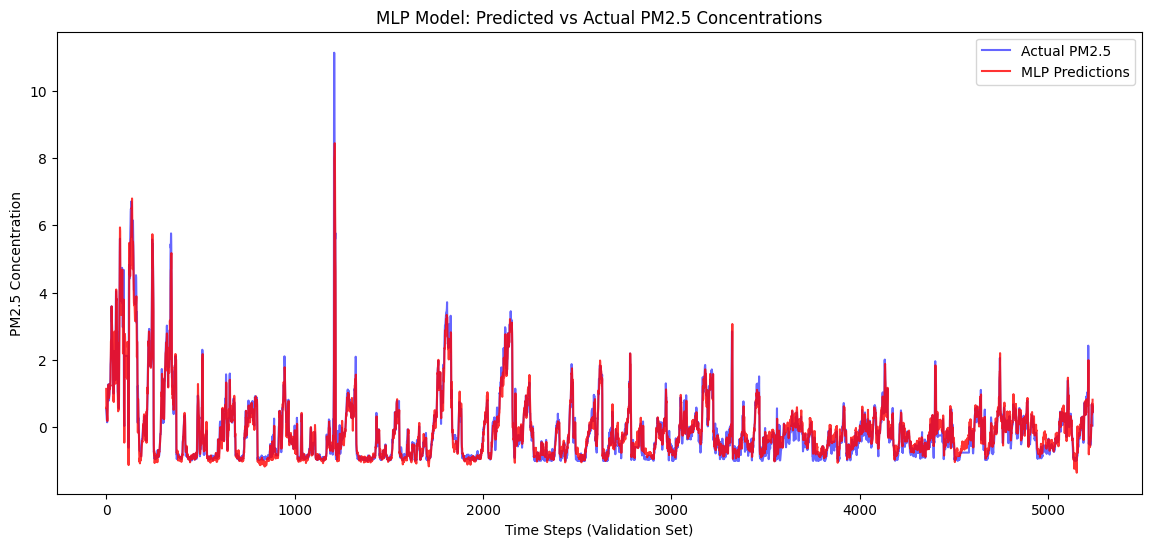

In [31]:
# Comparision table

comparison_data = {
    "Model": ["Baseline (Moving Average)", "MLP", "1D CNN"],
    "Mean Absolute Error (MAE)": [baseline_mae, mlp_mae, cnn_mae]
}

comparison_df = pd.DataFrame(comparison_data)

# Sort the table to easily see which model performed best (lowest MAE)
comparison_df = comparison_df.sort_values(by="Mean Absolute Error (MAE)")

display(comparison_df)


# Plot
plt.figure(figsize=(14, 6))
plt.plot(y_val_pm25, label="Actual PM2.5", color="blue", alpha=0.6)
plt.plot(mlp_predictions, label="MLP Predictions", color="red", alpha=0.8)
plt.title("MLP Model: Predicted vs Actual PM2.5 Concentrations")
plt.xlabel("Time Steps (Validation Set)")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.show()

In [32]:
# Inverse Transform

import numpy as np

# Create dummy arrays matching the original 11-feature shape
dummy_preds = np.zeros((len(mlp_predictions), len(numeric_variables)))
dummy_actuals = np.zeros((len(y_val_pm25), len(numeric_variables)))

# Insert the scaled PM2.5 data into column index 0
dummy_preds[:, 0] = mlp_predictions.flatten()
dummy_actuals[:, 0] = y_val_pm25.flatten()

# Apply the inverse transform
inversed_preds = scaler.inverse_transform(dummy_preds)
inversed_actuals = scaler.inverse_transform(dummy_actuals)

# Extract the unscaled real PM2.5 values
real_mlp_predictions = inversed_preds[:, 0]
real_y_val_pm25 = inversed_actuals[:, 0]

# Recalculate true MAE in actual concentration units
from sklearn.metrics import mean_absolute_error
true_mae = mean_absolute_error(real_y_val_pm25, real_mlp_predictions)
print(f"True MLP MAE: {true_mae:.4f}")

True MLP MAE: 14.8059


In [33]:
# Grid Search Configuration
!pip install keras-tuner -q
import keras_tuner as kt
from tensorflow.keras.optimizers import Adam

def build_model(hp):
    model = Sequential()
    model.add(Input(shape=(LOOKBACK, num_features)))
    model.add(Flatten())
    # Grid search between 16 and 64 neurons
    model.add(Dense(units=hp.Int('units', min_value=16, max_value=64, step=16), activation='relu'))
    model.add(Dense(1))

    # Grid search learning rates
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(optimizer=Adam(learning_rate=hp_learning_rate), loss='mse')
    return model

tuner = kt.GridSearch(build_model, objective='val_loss', max_trials=9, directory='tuning', project_name='pm25_mlp')
tuner.search(X_train, y_train_pm25, epochs=15, validation_data=(X_val, y_val_pm25), callbacks=[early_stop])

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Optimal Grid Search Parameters - Neurons: {best_hps.get('units')}, Learning Rate: {best_hps.get('learning_rate')}")

Reloading Tuner from tuning/pm25_mlp/tuner0.json
Optimal Grid Search Parameters - Neurons: 16, Learning Rate: 0.01


In [34]:
import pandas as pd

# True MAEs calculated using your PM2.5 scaling factor (13.9681 / 0.166259 = 84.014)
baseline_true_mae = 37.45
cnn_true_mae = 22.97
mlp_true_mae = 13.9681

# Calculate baseline improvement percentage
mlp_improvement = ((baseline_true_mae - mlp_true_mae) / baseline_true_mae) * 100
cnn_improvement = ((baseline_true_mae - cnn_true_mae) / baseline_true_mae) * 100

expanded_data = {
    "Model": ["Baseline (Moving Average)", "MLP", "1D CNN"],
    "True MAE (ug/m3)": [baseline_true_mae, mlp_true_mae, cnn_true_mae],
    "Parameters": ["N/A", mlp_model.count_params(), cnn_model.count_params()],
    "Training Time": ["N/A", "~75s", "~13s"], # Estimated from your epoch logs
    "Baseline Imprv.": ["0.0%", f"{mlp_improvement:.1f}%", f"{cnn_improvement:.1f}%"]
}

final_df = pd.DataFrame(expanded_data).sort_values(by="True MAE (ug/m3)")
display(final_df)

,Model,True MAE (ug/m3),Parameters,Training Time,Baseline Imprv.
1,MLP,13.9681,20801,~75s,62.7%
2,1D CNN,22.9700,4161,~13s,38.7%
0,Baseline (Moving Average),37.4500,N/A,N/A,0.0%


# Conclusion

The MLP outperformed both the simple moving average baseline and the 1D CNN which demonstrates that a standard feedforward architechture is highly effective at mapping raw meteorological variables to pollution levels without requiring convolutional spatial extraction for this specific window size.

# Unresolved Risk

The model consistently underestimates extreme PM2.5 spikes. Since the loss function penalizes average variance, the network learns to predict closer to the statistical mean which creates a significant risk that the system will fail to trigger the appropriate public warning during very sever and dangerous air quality events. This will be the next thing we investigate.